# Методы семантического анализа текстов

## Сходство между словами

You shall know a word by the company it keeps. 

*Firth*

 Варкалось. Хливкие шорьки<br>
   Пырялись по наве,<br>
   И хрюкотали зелюки,<br>
   Как мюмзики в мове.<br>

*Кэррол*

Не очень ясно что именно могут делать *зелюки*. Но если мы узнаем кто еще может *хрюкотать*, то мы можем посчитать, что нашли слово со сходным значением или, как минимум, относящееся к одной смысловой группе.

Аналогично мы не понимаем кто (что) такие *шорьки*. Если они бывают ответственными - это одно, если электронными - другое.

### Предобработка текста

Теперь возьмем новостные тексты с сайта Lenta.ru за лето 2018 года. Разделим каждый текст на предложения, а предложения на слова.

In [1]:
import numpy as np
import pandas as pd
import re
import nltk
import nltk.data
from tqdm.notebook import tqdm
import pymorphy3

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_extraction.text import CountVectorizer

nltk.download('punkt')

[nltk_data] Downloading package punkt to /home/edward/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /home/edward/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [2]:
# Файл в своем хитром формате, его просто надо порезать по разделителям.
with open("data/lenta2018.txt", encoding="utf-8") as newsfile: # Файл с новостями.
    text = newsfile.read()
    div_text = text.split("=====\n")[1:]
    text_news = [(n.split('\n')[0], '\n'.join(n.split('\n')[2:])) 
                 for n in div_text]
    news = pd.DataFrame(text_news, columns = ['Header', 'News'])

In [3]:
# Всё ли прочиталось?
news.head()

,Header,News
0,Раскрыто происхождение новейшей украинской кры...,Испытанная Украиной первая собственная крылата...
1,Русских гопников назвали настоящими древними с...,Пользователи Reddit выразили симпатию российск...
2,Поезд с американскими политиками врезался в му...,В американском штате Вирджиния пассажирский по...
3,Открыт первый европейский бордель с секс-кукла...,"Во Франции открылся первый бордель, который сд..."
4,Социологи подсчитали планирующих проголосовать...,На выборы президента собирается прийти 71 проц...


Давайте поделим тексты на предложения, а предложения на слова

In [4]:
def text_to_sentences(text):
    """ Функция делит текст на предложения, а предложения на слова.
    """
    
    # Поделим текст на предложения при помощи NLTK.
    raw_sentences = nltk.sent_tokenize(text, language="russian")
    # Поделим предложения на слова при помощи регулярных выражений, заодно выкинем знаки препинания и цифры.
    sentences = []
    for raw_sentence in raw_sentences:
        if len(raw_sentence) > 0:
            sentences.append(re.findall('[a-zA-Zа-яА-яёЁ]+', raw_sentence.lower()))
    return sentences

In [5]:
news['News'][11]

'Ракета-носитель «Союз-2.1а» с 11 спутниками стартовала с космодрома Восточный. Об этом сообщает Космический центр «Южный», который ведет прямую трансляцию запуска.Корабль должен доставить на орбиты 11 спутников, два из которых — российские спутники дистанционного зондирования Земли «Канопус-В» №3 и №4.Это уже третий пуск с Восточного. Предыдущий состоялся 28 ноября 2017 года и завершился неудачей — из-за неполадок с разгонным блоком была утеряна головная часть ракеты «Союз-2.1б» (с 19 спутниками на борту). В госкорпорации «Роскосмос» объяснили инцидент ошибкой в программном обеспечении разгонного блока и ракеты-носителя, заложенной еще 20 лет назад. Позже вице-премьер России Дмитрий Рогозин заявил, что при подготовке запуска сотрудники перепутали космодромы: «Союз-2.1б» запускали с Восточного, при этом параметры траектории рассчитали с учетом старта с Байконура.В ближайшие годы «Роскосмос» ставит задачу повысить долю успешных запусков ракет-носителей до 99 процентов.\n'

In [6]:
text_to_sentences(news['News'][11])[:2]

[['ракета',
  'носитель',
  'союз',
  'а',
  'с',
  'спутниками',
  'стартовала',
  'с',
  'космодрома',
  'восточный'],
 ['об',
  'этом',
  'сообщает',
  'космический',
  'центр',
  'южный',
  'который',
  'ведет',
  'прямую',
  'трансляцию',
  'запуска',
  'корабль',
  'должен',
  'доставить',
  'на',
  'орбиты',
  'спутников',
  'два',
  'из',
  'которых',
  'российские',
  'спутники',
  'дистанционного',
  'зондирования',
  'земли',
  'канопус',
  'в',
  'и',
  'это',
  'уже',
  'третий',
  'пуск',
  'с',
  'восточного']]

In [7]:
all_sentences = sum([text_to_sentences(x) for x in news['News']], [])

In [8]:
all_sentences[1]

['об',
 'этом',
 'пишет',
 'военный',
 'блог',
 'bmpd',
 'который',
 'ведут',
 'сотрудники',
 'московского',
 'центра',
 'анализа',
 'стратегий',
 'и',
 'технологий']

## Модель Word2Vec

Модель описана в статье [Т.Миколова и др.](https://papers.nips.cc/paper/5021-distributed-representations-of-words-and-phrases-and-their-compositionality.pdf) Идея метода основывается на оптимизации функционала, основанного на логарифмах вероятностей совместной встречаемости слов. Помимо этого, вводятся отрицательные примеры, вероятности которых не суммируются, а вычитаются. При этом отрицательных примеров берется больше, чем положительных.

Если говорить проще, то при обучении модель считает статистику, какое слово с каким сколько раз стояло рядом. За счет этого мы можем построить вектор частоты встречаемости слова с другими словами в одном окне текста заданной длины. Если два слова встречаются с одними и теми же словами с примерно одинаковой частотой (_котик кушает, бегает, спит, кусается_ и похожий на него _щенок кушает, бегает, спит, кусается, охраняет_), то это два похожих слова. Если два слова встречаются с разными словами (_котик кушает, бегает, спит, кусается_, но _электрон занимает орбиту, взаимодействует, перемещается_), значит это разные слова. У нас есть вектора слов большой размерности, нам надо впихнуть эти вектора в пространство меньшей размерности, положив похожие слова рядом, а непохожие - в разные места. Мы уже где-то встречали эту задачу! Но Миколов и др. использовали для ее решения простой персептрон.

Можно провести аналогию с SVD. У нас строится некоторое пространство, размерность которого определяется числом латентных переменных в системе - скрытых параметров, каждый из которых отвечает за какой-то "смысл": размер, цвет, политика, время, абстрактность, падеж слова и прочее. Количество признаков в этом пространстве определяется числом подобных скрытых переменных.

Не вникая в особенности устройства модели, научимся ею пользоваться.

Модель Gensym под новым Питоном не работает, будем делать руками.

### Использование предобученных моделей

У нас есть два пути:
- взять большое количество текстов и обучить на них собственную модель;
- найти модель, которую уже обучили добрые люди и выложили в сеть.

По первому пути не пойдём, пойдем по второму пути - загрузим модель, обученную разработчиками проекта [RusVectores](https://rusvectores.org/ru/models/) для русского языка на новостях. Я ее уже скачал и она лежит в каталоге `data`.

In [9]:
# Библиотека gensym больше не работает, но мы можем использовать что-то другое.
import gzip
import numpy as np
from sklearn.neighbors import BallTree
import hashlib

In [10]:
class Word2VecStorage:
    def __init__(self, filename):
        with gzip.open(filename, 'rt') as vector_file:
            text_vectors = vector_file.readlines()
        self.words, self.vectors = self.convert_vectors(text_vectors)
        del text_vectors
        self.tree = BallTree(self.vectors, leaf_size=20)
    
    def convert_vectors(self, text_vectors):
        count = int(text_vectors[0].split(' ')[0])
        size = int(text_vectors[0].split(' ')[1])
        words = dict()
        vectors = np.zeros((count, size))
        for index, text in enumerate(text_vectors[1:]):
            parts = text.split(' ')
            vectors[index, :] = np.array([float(x) for x in parts[1:]])
            words[parts[0]] = index
    
        return words, vectors

    def __getitem__(self, index):
        if type(index) == str:
            return self.vectors[self.words[index]]
        if type(index) == int:
            return self.vectors[index]
        raise TypeError('Index should be str or int')

    def most_similar(self, word, cnt=10):
        if type(word) == str:
            dists, indicies = self.tree.query(self.vectors[self.words[word]: self.words[word]+1, :], cnt)
            return [list(self.words.keys())[ind] for ind in indicies[0, 1:]]
        if type(word) == np.ndarray:
            dists, indicies = self.tree.query([word], cnt)
            return [list(self.words.keys())[ind] for ind in indicies[0, 1:]]
            
    

In [11]:
model_w2v = Word2VecStorage('data/araneum_upos_skipgram_300_2_2018.vec.gz')

Теперь можно получить представление слов в новом пространстве. Имейте в виду, что в данной модели слова сохранены с частями речи, чтобы различать разные значения!

In [12]:
model_w2v['огонь_NOUN'].shape[0], model_w2v['огонь_NOUN'][:8]

(300,
 array([-0.026901,  0.108851,  0.001131, -0.027662, -0.025068, -0.004586,
        -0.001261, -0.003796]))

In [13]:
model_w2v.most_similar('огонь_NOUN'), model_w2v.most_similar('интернет_NOUN'), model_w2v.most_similar('ученый_NOUN')

(['пламень_NOUN',
  'пылать_VERB',
  'потушить_VERB',
  'тушить_VERB',
  'зажигать_VERB',
  'костер_NOUN',
  'полыхать_VERB',
  'негасимый_ADJ',
  'шквальный_ADJ'],
 ['интеренет_NOUN',
  'интерент_NOUN',
  'интренет_NOUN',
  'интрнет_NOUN',
  'итернет_NOUN',
  'интенета_NOUN',
  'инетрнет_NOUN',
  'интерет_NOUN',
  'инетернет_NOUN'],
 ['исследователь_NOUN',
  'биолог_NOUN',
  'астрофизик_NOUN',
  'ученый_ADJ',
  'нейрофизиолог_NOUN',
  'нейробиолог_NOUN',
  'климатолог_NOUN',
  'зоолог_NOUN',
  'астроном_NOUN'])

 В полученном пространстве работают векторные операции. Если обучиться на достаточно большом количестве текстов, можно получить следующие эффекты.

![](img/w2v_vect.png)

![](img/w2v_vect2.png)


На хорошо обученной модели можно даже превратить индекс в город и наоборот при помощи векторных операций.

Попробуем эти векторные операции своими руками.

In [14]:
# Список всех слов
list(model_w2v.words.keys())[:20]

['год_NOUN',
 'мочь_VERB',
 'человек_NOUN',
 'время_NOUN',
 'работа_NOUN',
 'новый_ADJ',
 'становиться_VERB',
 'также_ADV',
 'очень_ADV',
 'день_NOUN',
 'первый_ADJ',
 'компания_NOUN',
 'являться_VERB',
 'ребенок_NOUN',
 'иметь_VERB',
 'система_NOUN',
 'место_NOUN',
 'получать_VERB',
 'большой_ADJ',
 'жизнь_NOUN']

Длины векторов нормированы.

In [15]:
lens = np.array([np.linalg.norm(model_w2v[word]) for word in model_w2v.words.keys()])
lens[lens > 1.01], lens[lens < 0.99], lens[0]

(array([], dtype=float64),
 array([], dtype=float64),
 np.float64(0.9999996401289353))

In [16]:
model_w2v.most_similar(model_w2v['король_NOUN']+model_w2v['женщина_NOUN']-model_w2v['мужчина_NOUN'])

['королева_NOUN',
 'герцог_NOUN',
 'монарх_NOUN',
 'генрих_PROPN',
 'людовик_PROPN',
 'франция::людовик_PROPN',
 'принц_NOUN',
 'королевство_NOUN',
 'наследный_ADJ']

In [17]:
model_w2v.most_similar(model_w2v['король_NOUN']-model_w2v['женщина_NOUN']+model_w2v['мужчина_NOUN'])

['герцог_NOUN',
 'генрих_PROPN',
 'принц_NOUN',
 'ярл_NOUN',
 'конунг_NOUN',
 'людовик_PROPN',
 'монарх_NOUN',
 'кронпринц_NOUN',
 'сюзерен_NOUN']

In [18]:
model_w2v.most_similar(model_w2v['король_NOUN']-model_w2v['женщина_NOUN']-model_w2v['мужчина_NOUN'])

['королевство_NOUN',
 'йиржи_NOUN',
 'илипп_NOUN',
 'валашский_ADJ',
 'гетман_NOUN',
 'морский_NOUN',
 'любомирский_NOUN',
 'негош_NOUN',
 'кобургский_ADJ']

In [19]:
model_w2v.most_similar(model_w2v['топливо_NOUN']-model_w2v['нефть_NOUN']+model_w2v['молоко_NOUN']), \
model_w2v.most_similar('молоко_NOUN')

(['топливо_NOUN',
  'творог_NOUN',
  'простокваша_NOUN',
  'ряженка_NOUN',
  'пастеризовать_VERB',
  'молозиво_NOUN',
  'зцм_X',
  'йогурт_NOUN',
  'сквашивать_VERB'],
 ['молока_NOUN',
  'ряженка_NOUN',
  'творог_NOUN',
  'пастеризовать_VERB',
  'кефир_NOUN',
  'ультрапастеризованный_ADJ',
  'простокваша_NOUN',
  'молозиво_NOUN',
  'кисломолочный_ADJ'])

In [20]:
model_w2v.most_similar(model_w2v['птица_NOUN']-model_w2v['крыло_NOUN']+model_w2v['плавник_NOUN']),

(['рыба_NOUN',
  'плавник_NOUN',
  'ракообразный_ADJ',
  'моллюск_NOUN',
  'тюлень_NOUN',
  'млекопитающее_NOUN',
  'рептилия_NOUN',
  'животное_NOUN',
  'колюшка_NOUN'],)

### Как устроено векторное пространство?

Давайте посмотрим на реальное расположение слов в этом пространстве. Для этого нам потребуется UMAP, а то как еще мы преобразуем 300-мерное пространство в плоскость? Просто преобразуем полученные от модели 300-мерные вектора в плоскость и полюбуемся результатом.

In [115]:
from umap import UMAP
from copy import copy
import pandas as pd

%matplotlib inline
import matplotlib.pyplot as plt
import plotly.express as px

plt.rcParams['figure.figsize'] = (16, 12)

Чтобы любоваться предметно, возьмем названия разных растений, условно разделенных на травы и деревья. Это поможет нам оценить, насколько близко или далеко оказываются сходные слова.

In [116]:
# Прочитаем слова из файлов.
trees = pd.read_csv("data/trees.txt", sep='\t', names=['trees'])
herbs = pd.read_csv("data/herbs.txt", sep='\t', names=['herbs'])
# Положим их в таблицы.
trees = trees['trees'].str.lower().unique()
herbs = herbs['herbs'].str.lower().unique()

In [117]:
def draw_plants(model_w2v, trees, herbs):
    """ Функция принимает на вход модель Word2Vec и списки деревьев и трав.
        Для каждого слова получается его вектор, вектора преобразуются к 2D и отрисовываются.
    """
    
    # Получаем вектора слов, заодно отсеивая слова, отсутствующие в модели.
    all_vect, all_names, all_types = [], [], []

    for plants, plant_type in zip([trees, herbs], [1, 0]):
        for m in plants:
            # Работать с Word2Vec можно немного по-разному...
            if m.strip().lower()+'_NOUN' in model_w2v.words.keys():
                # Но нам в любом случае надо проверить если слово в модели и добавить его вектор.
                all_vect.append(model_w2v[m.strip().lower()+'_NOUN'])
                all_names.append(m)
                all_types.append(plant_type)

    # Преобразовываем к 2D.
    umaped_vct=UMAP().fit_transform(all_vect)
    
    # Рисуем все слова, деревья и травы разным цветом.
    fig, ax = plt.subplots()
    fig.set_size_inches(15,10)
    ax.scatter(umaped_vct[:, 0], umaped_vct[:, 1], c=all_types, s=3)

    # Смотрим куда попали родовые понятия, рисуем их красным.
    for word in ['фрукт', 'овощ', 'ягода', 'приправа', 'пряность', 'дерево', 'трава', 'цветок', 'куст']:
        ind = all_names.index(word)
        ax.scatter(umaped_vct[ind, 0], umaped_vct[ind, 1], c='r', s=7)

    # Добавляем названия для нарисованных точек.
    for n, v in zip(all_names, umaped_vct):
        ax.annotate(n, (v[0], v[1]))

    plt.show()
    return all_vect, all_names

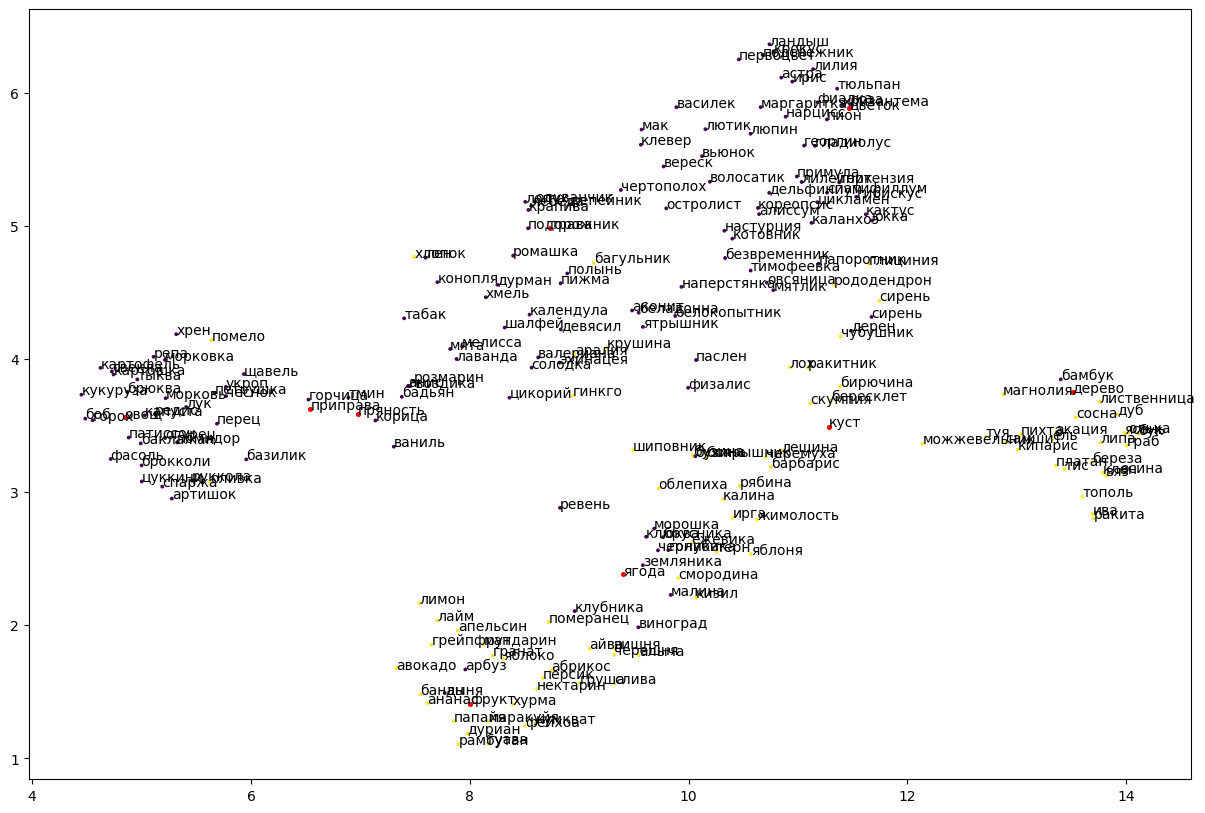

In [118]:
all_vect, all_names = draw_plants(model_w2v, trees, herbs)

А теперь давайте добавим ещё одно измерение и посмотрим, как точки будут меняться вдоль него.

In [119]:
from ipywidgets import interact, FloatSlider

In [120]:
umaped_vct = UMAP(n_components=3).fit_transform(all_vect)

In [121]:
def drawHerbs(val):
    fig, ax = plt.subplots()
    fig.set_size_inches(15,10)
    temp_data = np.array([u for u in umaped_vct if u[2]>=val-0.5 and u[2]<=val+0.5])
    temp_names = [all_names[i] for i, u in enumerate(umaped_vct) if u[2]>=val-0.5 and u[2]<=val+0.5]
    
    ax.scatter(temp_data[:, 0], temp_data[:, 1], c=temp_data[:, 2], s=30)

    for word in ['фрукт', 'овощ', 'ягода', 'приправа', 'пряность', 'дерево', 'трава', 'цветок', 'куст']:
        ind = all_names.index(word)
        ax.scatter(umaped_vct[ind, 0], umaped_vct[ind, 1], c='r', s=7)
        ax.annotate(word, (umaped_vct[ind, 0], umaped_vct[ind, 1]))

    for n, v in zip(temp_names, temp_data):
        ax.annotate(n, (v[0], v[1]))

    plt.show()

In [122]:
# sld1 = FloatSlider(value=(min(umaped_vct[:, 2])+max(umaped_vct[:, 2]))/2, 
sld1 = FloatSlider(value=(min(umaped_vct[:, 2])+max(umaped_vct[:, 2]))/2, 
                   min=min(umaped_vct[:, 2]), max=max(umaped_vct[:, 2]), 
                   step=0.1, description='Filter by Z')

interact(drawHerbs, val=sld1);

interactive(children=(FloatSlider(value=3.551652669906616, description='Filter by Z', max=7.83257532119751, mi…

----

## Векторизация текстов

Работать с векторами слов бывает очень полезно. Так, например, если нам нужно подать на вход нейросети вектор предложения, то мы можем предположить, что предложения не содержат больше 200 слов. Тогда на потребуется вектор длины `200 * 300 = 60 000` чтобы отдать любое предложение. На место имеющихся слов запишем их вектор, на место тех, что выходят за длину предложения - нули. 

Но иногда бывает необходимо работать с текстом как вектором. В такой ситуации удобно взять векторы всех слов в тексте и посчитать их средний вектор, считая что именно он будет представлять некоторый усредненный "смысл" текста.

Так как нам теперь придется работать не просто с начальными формами слов, а с их векторами, а вектора в имеющейся модели можно получить только по начальной форме и части речи, то нам необходимо написать фунцию для разметки текстов так, чтобы выход содержал в себе и часть речи. Заодно будем брать только слова со значимыми частями речи: прилагательные, существительные и глаголы.

In [29]:
# Список значимых частей речи.
conv_pos = {'ADJF':'ADJ', 'ADJS':'ADJ', 'ADV':'ADV', 'NOUN':'NOUN',
            'VERB':'VERB', 'PRTF':'ADJ', 'PRTS':'ADJ', 'GRND':'VERB'}
tmp_dict = {}
nones = {}

# Фильтруем по части речи и возвращаем только начальную форму.
def normalizePymorphy(text, morph):
    tokens = re.findall('[A-Za-zА-Яа-яЁё]+-[A-Za-zА-Яа-яЁё]+|[A-Za-zА-Яа-яЁё]+', text)
    words = []
    for t in tokens:
        if t in tmp_dict.keys():
            words.append(tmp_dict[t])
        elif t in nones.keys():
            pass
        else:
            pv = morph.parse(t)
            if pv[0].tag.POS != None:
                if pv[0].tag.POS in conv_pos.keys():
                    words.append(pv[0].normal_form+"_"+conv_pos[pv[0].tag.POS])
                    tmp_dict[t] = pv[0].normal_form+"_"+conv_pos[pv[0].tag.POS]
                else:
                    nones[t] = ""
                    
    return words

Теперь посмотрим какова размерность векторов, хранимых в модели, и сколько в ней слов.<br>
Размерность векторов 300 - с запасом. Почти 200 000 слов - тоже очень хорошо.

У нас есть смысл отдельных слов. Построим на его основе смысл текста как среднее арифметическое всех векторов для слов, составляющих данный текст.

In [39]:
index2word_set = set(model_w2v.words)

def text_to_vec(text):
    text_vec = np.zeros((300,), dtype="float32")
    n_words = 0
    morph = pymorphy3.MorphAnalyzer()

    for word in normalizePymorphy(text, morph):
        if word in index2word_set:
            n_words = n_words + 1
            text_vec = np.add(text_vec, model_w2v[word]) 
    
    if n_words != 0:
        text_vec /= n_words
    return text_vec


Рассчитаем вектора всех текстов - они нам еще пригодятся.

In [40]:
w2v_vectors = [text_to_vec(text) for text in news.News]

Найдем текст, самый похожий на некоторый текст.

In [41]:
vpos = 72
v1 = text_to_vec(news.News[vpos])

ms = np.argmin([np.linalg.norm(v1-w2v_vectors[i]) for i in range(news.News.shape[0]) if i!=vpos])
print(news.News[vpos])
if ms>vpos:
    print(ms+1, news.News[ms+1])
else:
    print(ms, news.News[ms])

В одной из больниц Флориды скончался американец Ли Гоггин, который попал под обвал дюны на одном из городских пляжей. Об этом на своей странице в Facebook рассказала сестра погибшего Рейчел.Мужчина находился в состоянии медикаментозной комы в течение двух дней и умер от остановки сердца. Ему было 33 года. У него остались жена и трое детей.Материалы по теме00:09 — 17 январяБомбический отдыхЧто делать туристу во время ядерной войныРанее сообщалось, что инцидент произошел в воскресенье, 28 января, на пляже Кресент во Флориде. Ли Гоггин из Техаса отдыхал с семьей и решил ради шутки закопать себя в песок. Внезапно туннель, который он вырыл, обрушился под ним, и мужчину засыпало песком от расположенных вокруг дюн. В отчете полиции говорится, что члены семьи пытались выкопать мужчину самостоятельно, однако у них ничего не вышло, и они вызвали службу спасения.Спасатели извлекли Гоггина в состоянии остановки сердца из ямы глубиной около метра, где он провел около 30 минут. После восстановления 

Теперь посмотрим как распределятся тексты в новом пространстве.

In [42]:
umap_news = UMAP()
umaped_vct = umap_news.fit_transform(w2v_vectors)

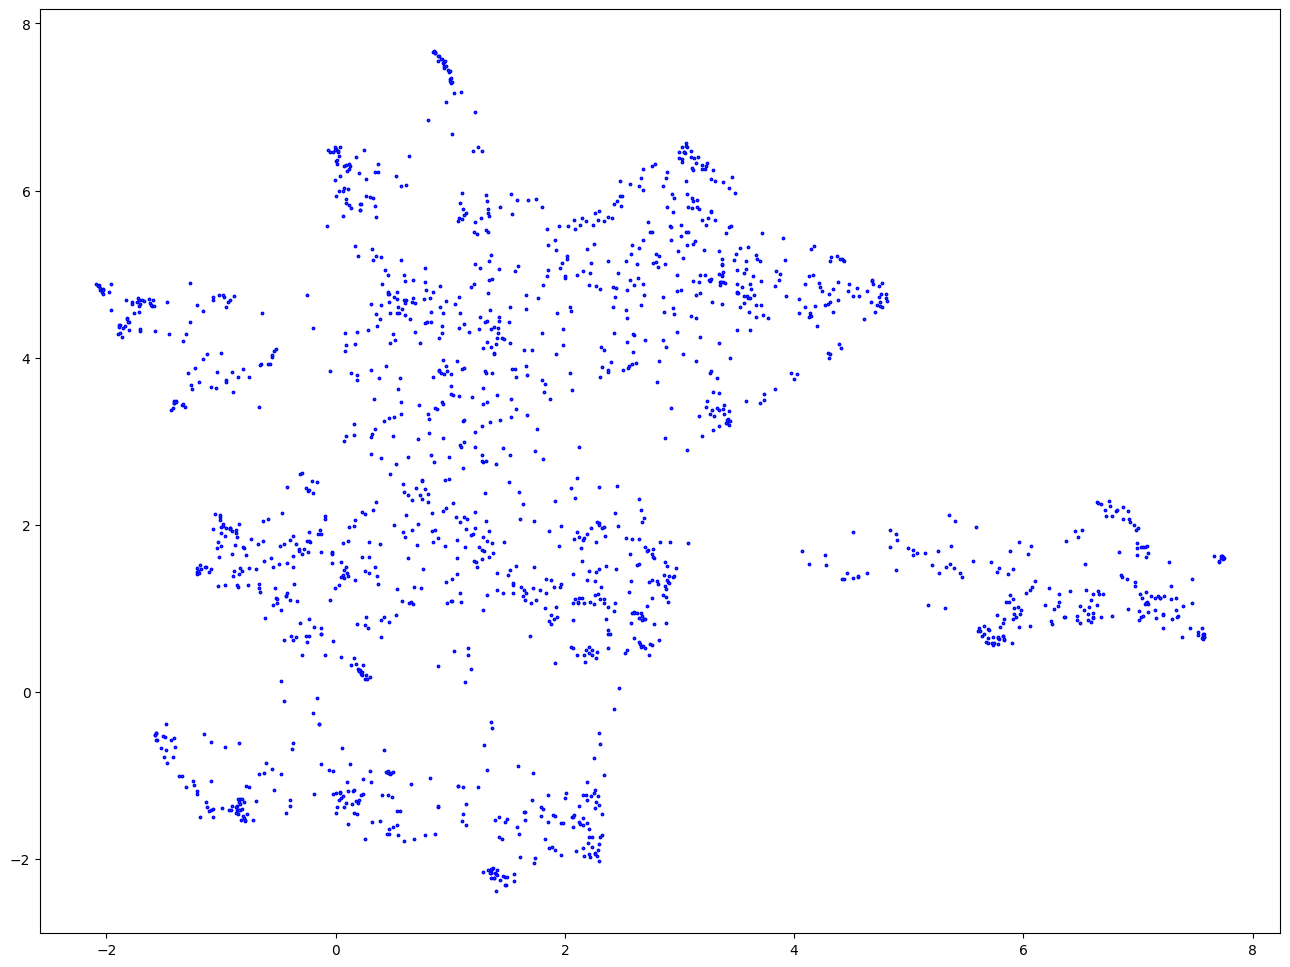

In [43]:
fig, ax = plt.subplots()
ax.scatter(umaped_vct[:, 0], umaped_vct[:, 1], edgecolor='b', s=3)
plt.show()

## BERT

Bert исправляет сразу несколько недостатков, которые имеются у Word2Vec. Во-первых, как и FastText, он разбивает слова на части и приписывает вектора именно им. Помимо этого, вектор приписывается слову в контексте. Если слово обладает несколькими значениями, контекст может помочь определить конкретное значение употребления этого слова. По данному признаку все модели делятся на статические и контекстуализированные. Статические, такие как Word2Vec и FastText, возвращают вектор по слову. Контекстуализированные, такие как Bert и Elmo, получают на вход предложение, используют его как контекст и возвращают векторы для всех слов (частей слов) предложения.

Word2Vec обучает нейронную сеть, получает с ее помощью векторы для всех слов, а дальше работает как словарь. В основе Bert лежит более умная нейронная сеть, и Bert применяет ее для того, чтобы вывести вектор для всех слов в переданном тексте. То есть Word2Vec хранит словарь, Bert хранит веса нейросети.

Итак, вместо самих слов мы можем использовать их векторные представления в некотором семантическом пространстве.
![](img/cartoon-espresso-word2vec.jpg)

Беда Word2Vec состоит в том, что он генерирует только один вектор на каждое слово. То есть он не различает различных смыслов одного слова.
![](img/cartoon-citizen-data-scientist.jpg)

In [47]:
!pip install --break-system-packages --upgrade transformers torch torchvision torchaudio

Defaulting to user installation because normal site-packages is not writeable


In [48]:
from transformers import AutoTokenizer, AutoModel
import torch
from sklearn.metrics.pairwise import cosine_similarity
from tqdm import tqdm

from umap import UMAP
# from copy import copy

%matplotlib inline
import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns

plt.rcParams['figure.figsize'] = (16, 12)

Загрузим модель `DeepPavlov/rubert-base-cased-sentence`, созданную DeepPavlov и обученную на предложениях.

Также попробуем сказать PyTorch, на котором написана модель, что надо попытаться работать с CUDA, а если не получится - на процессоре.

In [57]:
# tokenizer = AutoTokenizer.from_pretrained("DeepPavlov/rubert-base-cased-sentence")
# model = AutoModel.from_pretrained("DeepPavlov/rubert-base-cased-sentence")
tokenizer = AutoTokenizer.from_pretrained("DeepPavlov/rubert-base-cased")
model = AutoModel.from_pretrained("DeepPavlov/rubert-base-cased")

# device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")
device = torch.device("cpu")
model.to(device);

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: DeepPavlov/rubert-base-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


У токенизатора есть множество параметров. 
- `return_tensors` - повзволяет выбрать, какой тип данных должен быть на выходе. Есть вариант `tf` (`tensorflow`), `pt` (`pytorch`) и  `np` (`numpy`). Если не указано, то вернет просто списки.  
- `padding` - задает, нужен ли и какой паддинг (дополнение) входа. Умеет дополнять: до самой большой длины входа или до максимальной длины, указанной в параметре.  
- `truncation` - нужно ли обрезать последовательность.  
- `max_length` - максимальная длина последовательности.  


In [58]:
tokenizer.tokenize('Что ты здесь делаешь?')

['Что', 'ты', 'здесь', 'дела', '##ешь', '?']

In [59]:
tokenizer.encode('Что ты здесь делаешь?')

[101, 13302, 4609, 10378, 11725, 26318, 166, 102]

In [60]:
tokenizer.decode(tokenizer.encode('Что ты здесь делаешь?'))

'[CLS] Что ты здесь делаешь? [SEP]'

In [61]:
list(tokenizer.vocab.items())[:10]

[('соперниками', 54008),
 ('Хельсинкской', 119128),
 ('##адом', 43251),
 ('кончине', 87061),
 ('лежал', 58674),
 ('сообщают', 25426),
 ('坎', 3528),
 ('становились', 31883),
 ('южно', 23838),
 ('взлётно', 50683)]

Теперь посморим какие векторы возвращает модель. Сама модель тоже умеет работать как вызываемый объект.

In [62]:
text_1 = "папа мыл раму"
encoded_text = tokenizer(text_1, return_tensors='pt')
# output = model(**encoded_text)
output = model(**{k: v.to(model.device) for k, v in encoded_text.items()})


In [63]:
encoded_text

{'input_ids': tensor([[   101,  24820,   8235,    864, 102556,    102]]), 'token_type_ids': tensor([[0, 0, 0, 0, 0, 0]]), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1]])}

In [65]:
dir(output)

['__annotate_func__',
 '__annotations_cache__',
 '__class__',
 '__class_getitem__',
 '__contains__',
 '__dataclass_fields__',
 '__dataclass_params__',
 '__delattr__',
 '__delitem__',
 '__dict__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__firstlineno__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__getitem__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__ior__',
 '__iter__',
 '__le__',
 '__len__',
 '__lt__',
 '__match_args__',
 '__module__',
 '__ne__',
 '__new__',
 '__or__',
 '__post_init__',
 '__reduce__',
 '__reduce_ex__',
 '__replace__',
 '__repr__',
 '__reversed__',
 '__ror__',
 '__setattr__',
 '__setitem__',
 '__sizeof__',
 '__static_attributes__',
 '__str__',
 '__subclasshook__',
 'attentions',
 'clear',
 'copy',
 'cross_attentions',
 'fromkeys',
 'get',
 'hidden_states',
 'items',
 'keys',
 'last_hidden_state',
 'move_to_end',
 'past_key_values',
 'pooler_output',
 'pop',
 'popitem',
 'setdefault',
 'to_tuple',
 'update',
 'values']

In [66]:
output.keys()

odict_keys(['last_hidden_state', 'pooler_output'])

In [67]:
output.last_hidden_state.shape

torch.Size([1, 6, 768])

In [68]:
for id in encoded_text['input_ids'][0]:
    print(id, tokenizer.decode(id))

tensor(101) [CLS]
tensor(24820) папа
tensor(8235) мы
tensor(864) ##л
tensor(102556) раму
tensor(102) [SEP]


Помимо собственно векторов, мы можем получить матрицу внимания, которая показывает связи между токенами.

In [70]:
toks = tokenizer(text_1, padding='max_length', truncation=True, return_tensors='pt',
          max_length=16)
with torch.no_grad():
    model_output = model(**{k: v.to(model.device) for k, v in toks.items()},
                         output_attentions=True,
                         output_hidden_states=True)

[transformers] `sdpa` attention does not support `output_attentions=True`. Please set your attention to `eager` if you want any of these features.


In [74]:
model_output.hidden_states[0][:3, :3]

tensor([[[ 1.0899,  0.6695,  0.1660,  ..., -0.4907, -0.6739,  0.4493],
         [ 0.0850, -0.0755, -0.6208,  ...,  0.5659,  0.5554,  0.7596],
         [-0.1322,  0.3856,  0.7329,  ..., -1.2313,  0.3896, -0.1992]]])

Исследуем как себя ведёт Bert в разных ситуациях.

In [81]:
def encode_sentence1(text, tokenizer, model):
    encoded_text = tokenizer(text, return_tensors='pt')
    output = model(**{k: v.to(model.device) for k, v in encoded_text.items()})
    return output.last_hidden_state[0]

def encode_sentence2(text, tokenizer, model):
    encoded_text = tokenizer(text, return_tensors='pt')
    model.embeddings.word_embeddings(encoded_text['input_ids'])
    return output.last_hidden_state[0]

"Папа" в разных контекстах не похож сам на себя.

In [82]:
s1 = encode_sentence1("папа моет раму", tokenizer, model)
s2 = encode_sentence1("папа строит дом", tokenizer, model)
s3 = encode_sentence1("папа чистит раму", tokenizer, model)
s4 = encode_sentence1("папа мыл раму", tokenizer, model)
s5 = encode_sentence1("папа пьет виски", tokenizer, model)
s6 = encode_sentence1("добрый папа пьет виски", tokenizer, model)
s7 = encode_sentence1("коптроваркующийся папа моет раму", tokenizer, model)
s8 = encode_sentence1("папа моет раму и папа пьет виски", tokenizer, model)
s9 = encode_sentence1("папе моют раму", tokenizer, model)
s10 = encode_sentence1("раму моют папой", tokenizer, model)


In [20]:
s1

tensor([[ 0.0831, -0.0051,  0.0389,  ..., -0.1504, -0.0805, -0.1175],
        [ 0.2136, -0.4037,  0.6854,  ..., -0.6857, -0.2095,  0.0375],
        [ 0.2684,  0.2717,  1.2009,  ..., -0.4627, -0.6502, -0.3207],
        [ 1.2402,  0.6413,  0.7489,  ...,  0.9041, -0.3603, -0.9716],
        [ 0.3117, -0.1110,  0.6440,  ...,  0.0072, -0.5943, -0.4562],
        [ 0.2395,  0.3454, -0.1991,  ..., -0.6532, -0.1458,  0.3672]],
       grad_fn=<SelectBackward0>)

In [83]:
s2[1].detach().numpy()[:10]

array([ 0.11814224, -0.24624974,  0.5890889 , -0.31269187,  0.11233801,
       -0.09678756,  0.11006685, -0.00134948,  0.62519616,  0.46196738],
      dtype=float32)

In [84]:
cosine_similarity([s5[1].detach().numpy()], [s1[1].detach().numpy()])

array([[0.75508404]], dtype=float32)

In [85]:
def text_to_Bert_vect(text, tokenizer, model):
    try:
        vectors = encode_sentence1(text, tokenizer, model)
        vectors = vectors.detach().numpy().mean(axis=0)
        return vectors
    # Размер входной последовательности ограничен 512 токенами. 
    # Мне не хочется делать цикл по фрагментам, а потом усреднять по ним, поэтому вернем при ошибке нулевой вектор.
    except:
        return np.zeros((768))

In [86]:
bert_vectors = []
for text in tqdm(news.News):
    bert_vectors.append(text_to_Bert_vect(text, tokenizer, model))

100%|█████████████████████████████████████████████████████████████████████████████| 1708/1708 [06:17<00:00,  4.52it/s]


In [87]:
umap_news = UMAP()
umaped_vct = umap_news.fit_transform(bert_vectors)

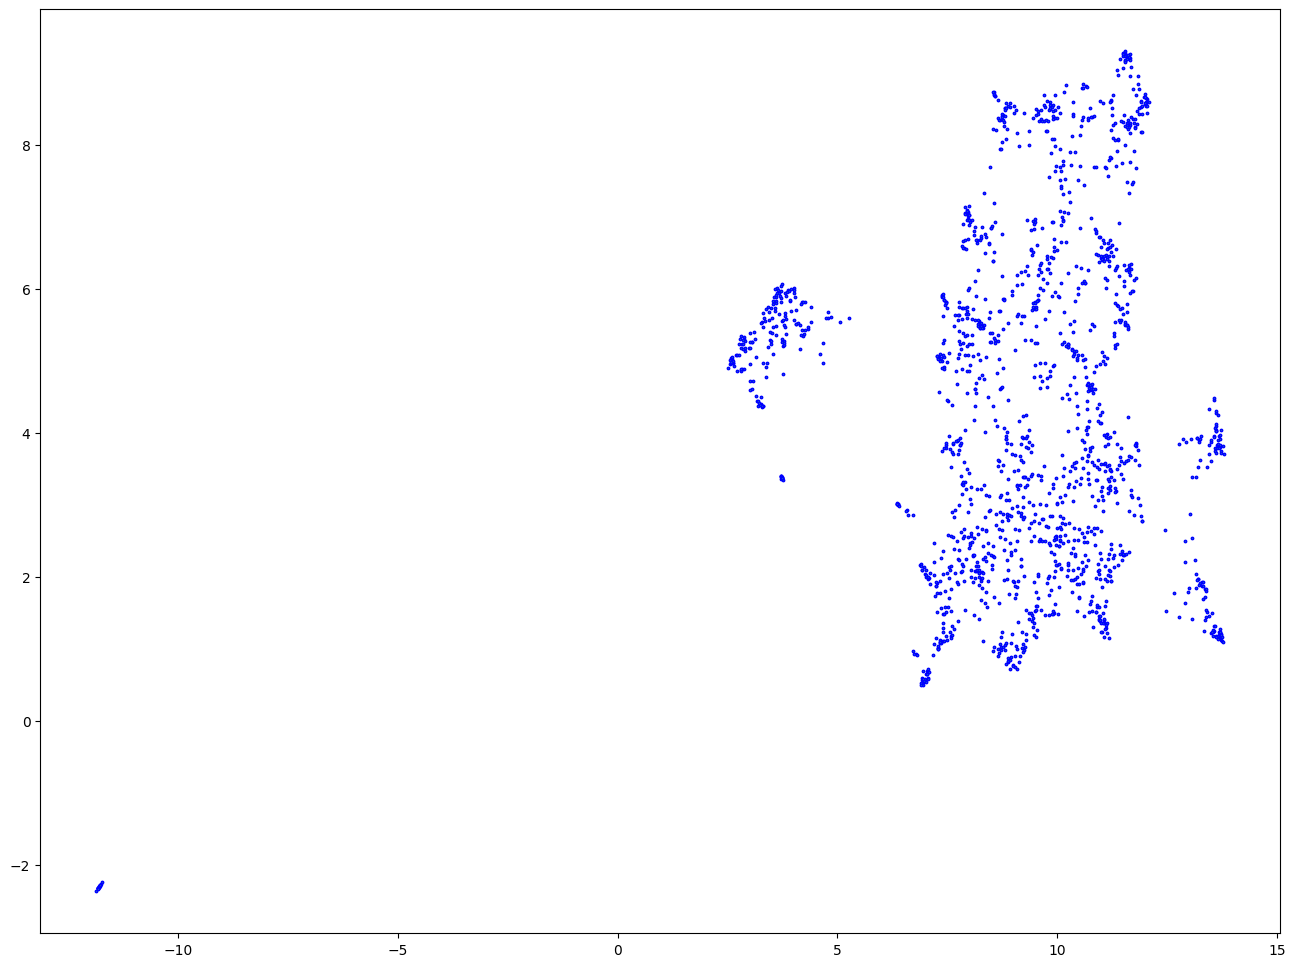

In [88]:
fig, ax = plt.subplots()
ax.scatter(umaped_vct[:, 0], umaped_vct[:, 1], edgecolor='b', s=3)
plt.show()

In [98]:
from transformers import AutoTokenizer, AutoModel
import torch
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.cluster import DBSCAN
from tqdm import tqdm
import seaborn as sns
from matplotlib.colors import ListedColormap
from numpy.random import choice

In [ ]:
!!! Надо заменить модель !!!

In [47]:
# tokenizer = AutoTokenizer.from_pretrained("DeepPavlov/rubert-base-cased-sentence")
# model = AutoModel.from_pretrained("DeepPavlov/rubert-base-cased-sentence")
tokenizer = AutoTokenizer.from_pretrained("DeepPavlov/rubert-base-cased")
model = AutoModel.from_pretrained("DeepPavlov/rubert-base-cased")

device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")
model.to(device);

Some weights of the model checkpoint at DeepPavlov/rubert-base-cased were not used when initializing BertModel: ['cls.predictions.bias', 'cls.predictions.decoder.bias', 'cls.predictions.decoder.weight', 'cls.predictions.transform.LayerNorm.bias', 'cls.predictions.transform.LayerNorm.weight', 'cls.predictions.transform.dense.bias', 'cls.predictions.transform.dense.weight', 'cls.seq_relationship.bias', 'cls.seq_relationship.weight']
- This IS expected if you are initializing BertModel from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertModel from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


In [89]:
def cluster_texts_and_draw(vectors, umaped_vct, eps):
    """ Функция кластеризует вектора vectors при помощи DBSCAN, используя eps в качестве параметра,
        и отображает их на плоскость, используя umaped_vct.
    """
    # Кластеризуем данные при помощи DBSCAN. 
    # Это не значит, что он лучше k-Means, он просто здесь быстрее.
    db = DBSCAN(eps=eps, min_samples=5)
    db_clusters = db.fit_predict(vectors)
     # Генерируем контрастную карту цветов.
    myclr = ListedColormap(choice(list(sns.xkcd_rgb.values()), max(db_clusters)+1))
    print(max(db_clusters))
    fig, ax = plt.subplots()
    ax.scatter(umaped_vct[:, 0], umaped_vct[:, 1], s=3, c=db_clusters, cmap=myclr)
    plt.show()
    return db_clusters

def show_texts_in_clusters(texts, target, clust_no, text_no):
    """ Функция отображает группировку текстов texts по кластсерам target.
        Выводит не более text_no текстов из первых clust_no кластеров.
    """

    clusters = list(set(target))

    for c in clusters[:clust_no]:
        print('          __ ', c, ' __')
        cntr = 0
        for i, a in enumerate(texts):
            if target[i] == c:
                print(a[:200])
                cntr += 1
                if cntr == text_no:
                    break
        print()

Для того, чтобы применить DBSCAN давайте сперва определим среднее расстояние до 5 самых близких точек для каждого текста. Теперь мы можем прикинуть с какого начального значения можно начинать подбирать $\epsilon$.

100%|████████████████████████████████████████████████████████████████████████████| 1708/1708 [00:06<00:00, 244.10it/s]


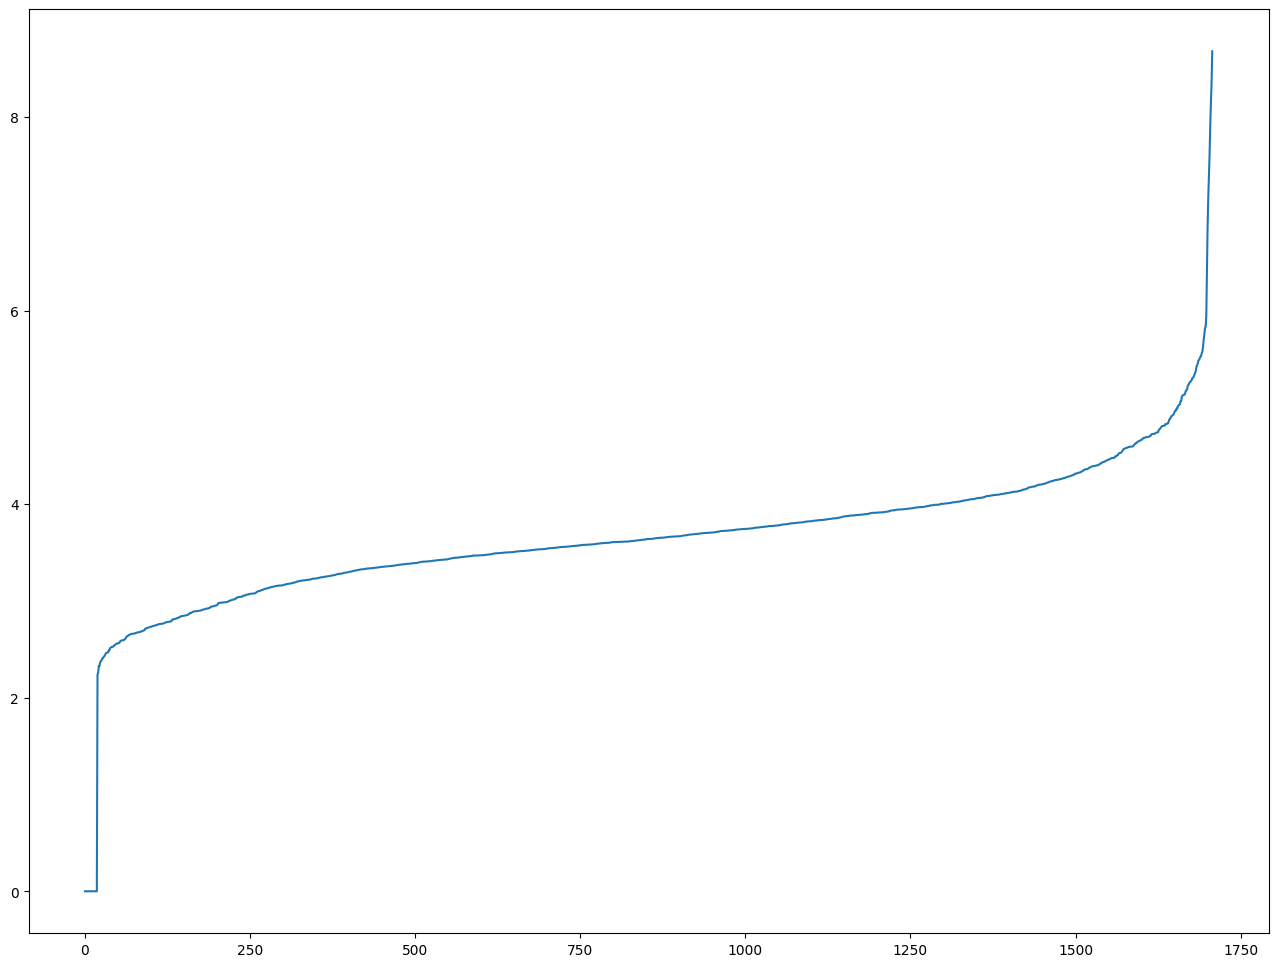

In [110]:
neighbours=[]
for v1 in tqdm(bert_vectors):
    neighbours.append(np.mean(sorted([np.linalg.norm(v1-v2) for v2 in bert_vectors])[1:6]))
neighbours=sorted(neighbours)
fig, ax = plt.subplots()
ax.plot(range(len(neighbours)), neighbours)
plt.show()

18


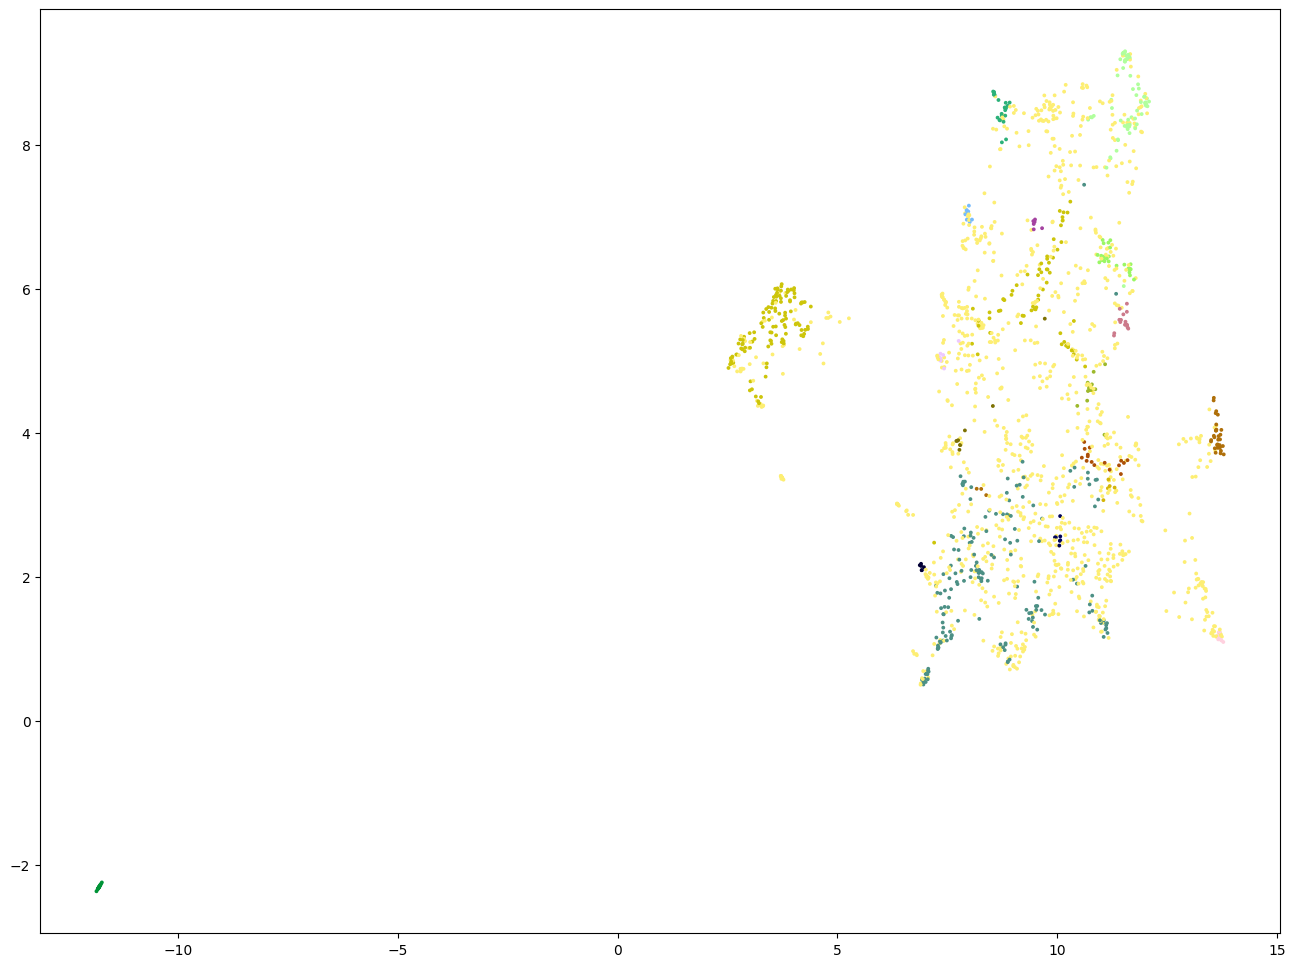

In [113]:
clusters = cluster_texts_and_draw(bert_vectors, umaped_vct, 3.45)

In [114]:
show_texts_in_clusters(news['News'], clusters, 10, 3)

          __  0  __
Сотрудники ФСБ задержали звезду телесериала «Детективы» Алексея Насонова. Об этом в четверг, 1 февраля, сообщает «Росбалт» со ссылкой на осведомленный источник.Ранее работавший участковым Насонов откр
Пресненский суд Москвы признал бывшего губернатора Кировской области Никиту Белых виновным в получении взятки должностным лицом. Об этом в четверг, 1 февраля, сообщает корреспондент «Ленты.ру» из зала
Пресненский суд Москвы приговорил бывшего губернатора Кировской области Никиту Белых к восьми годам лишения свободы. Об этом в четверг, 1 февраля, из зала суда сообщает корреспондент «Ленты.ру».Осужде

          __  1  __
Международная группа ученых под руководством испанского университета Гранады выяснила, что долгосрочное употребление в пищу подсолнечного масла или рыбьего жира может привести к воспалительным процесс
Международная группа ученых из Великобритании и Германии идентифицировала 24 новых препарата, которые потенциально останавливают старение и продлевают жизн